TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Downloaded from: https://www.gutenberg.org/cache/epub/1661/pg1661.txt

Title : The Adventures of Sherlock Holmes | Author: Arthur Conan Doyle | Released: March 1, 1999 [eBook #1661]
Raw file: 581,601 chars -> 119,654 tokens after cleaning (104,468 words + 15,186 punctuation)
Unique tokens: 8,236 | appearing only once: 3,826
Sentences: 7,267 | mean 15.5 tokens | median 12 | 95th pct 40
Top-15 tokens: [(',', 7659), ('.', 6185), ('the', 5611), ('and', 3009), ('i', 3000), ('to', 2684), ('of', 2647), ('a', 2641), ('in', 1762), ('that', 1744), ('it', 1701), ('you', 1481), ('he', 1467), ('was', 1410), ('his', 1159)]

Vocabulary size: 2,722 (tokens seen >= 3x in train; the rest -> <unk>)
<unk> rate  train 6.2% | val 8.1% | test 9.0%
Sequences  train (95703, 20) | val (11945, 20) | test (11946, 20)   (X = 20 word ids, y = next word id)

INPUT : the adventures of sherlock holmes by <unk> <unk> <unk> conte

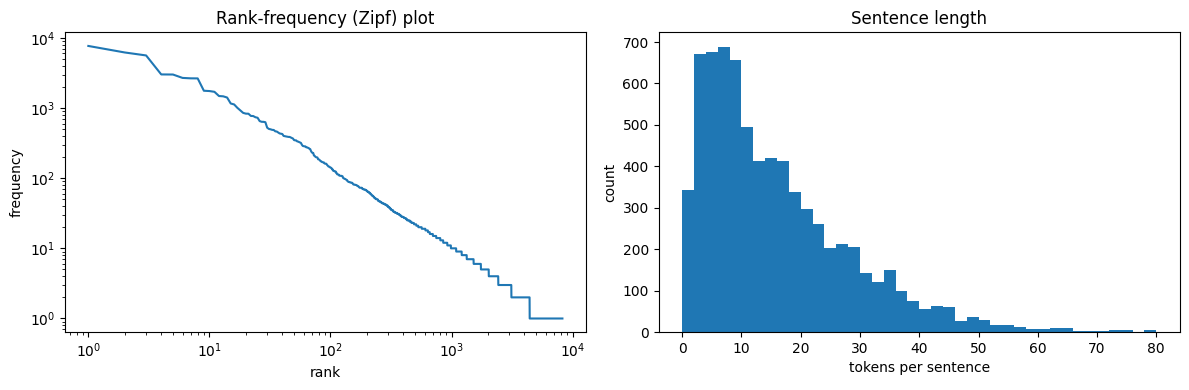


Saved: data/prepared.npz, data/vocab.json, results/dataset_overview.png


In [6]:
# Task (i) Part 1 - loading the dataset, cleaning it and making input/target sequences
# Dataset: The Adventures of Sherlock Holmes - Arthur Conan Doyle
# Source: Project Gutenberg eBook #1661 -> https://www.gutenberg.org/ebooks/1661

import os
import re
import json
import unicodedata
import urllib.request
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

SEED = 42
SEQ_LEN = 20     # how many previous words the model sees
MIN_COUNT = 3    # words appearing less than this in train -> <unk>

keras.utils.set_random_seed(SEED)
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))


# 1. Download the book (trying 3 links in case one doesn't work)
urls = ["https://www.gutenberg.org/cache/epub/1661/pg1661.txt",
        "https://www.gutenberg.org/ebooks/1661.txt.utf-8",
        "https://www.gutenberg.org/files/1661/1661-0.txt"]

raw = None
for url in urls:
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        raw = urllib.request.urlopen(req, timeout=60).read().decode("utf-8-sig")
        raw = raw.replace("\r", "")
        print("Downloaded from:", url)
        break
    except Exception as e:
        print("Failed:", url, "->", e)

if raw is None:
    raise RuntimeError("Download failed, upload the txt file manually")

with open("data/sherlock_raw.txt", "w", encoding="utf-8") as f:
    f.write(raw)


def get_header(field):
    # gutenberg files have lines like "Title: ..." at the top
    m = re.search(r"^" + field + r":\s*(.+)$", raw, re.M | re.I)
    if m:
        return m.group(1).strip()
    return "n/a"


# 2. Cleaning
# remove the Project Gutenberg licence text before and after the book
start = re.search(r"\*\*\* ?START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK[^\n]*", raw)
end = re.search(r"\*\*\* ?END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK", raw)
text = raw[start.end():end.start()]

# remove headings (lines that are completely in capital letters)
lines = []
for line in text.split("\n"):
    if line.strip() and line.strip().isupper():
        continue
    lines.append(line)
text = "\n".join(lines)

text = re.sub(r"\[[^\]]*\]", " ", text)             # remove [Illustration] tags
text = text.replace("’", "'").replace("‘", "'")     # curly quotes -> normal quotes
text = text.replace("“", '"').replace("”", '"')
text = text.replace("—", " ").replace("–", " ")     # dashes -> space
text = text.replace("_", "")                        # _italics_ markers

# remove accents (é -> e) and make everything lowercase
text = unicodedata.normalize("NFKD", text)
text = "".join(ch for ch in text if not unicodedata.combining(ch))
text = text.lower()

# tokenise: words (can contain ' or - like don't, well-known) and punctuation . , ; : ! ?
tokens = re.findall(r"[a-z]+(?:['-][a-z]+)*|[.,;:!?]", text)


# 3. Some statistics about the dataset
counts = Counter(tokens)
n_tokens = len(tokens)
n_words = sum(c for w, c in counts.items() if w[0].isalpha())
n_punct = n_tokens - n_words
n_once = sum(1 for c in counts.values() if c == 1)

# sentence length = number of tokens between . ! ?
sent_lengths = []
count = 0
for t in tokens:
    if t in [".", "!", "?"]:
        if count > 0:
            sent_lengths.append(count)
        count = 0
    else:
        count += 1

print("\nTitle :", get_header("Title"), "| Author:", get_header("Author"), "| Released:", get_header("Release date"))
print(f"Raw file: {len(raw):,} chars -> {n_tokens:,} tokens after cleaning ({n_words:,} words + {n_punct:,} punctuation)")
print(f"Unique tokens: {len(counts):,} | appearing only once: {n_once:,}")
print(f"Sentences: {len(sent_lengths):,} | mean {np.mean(sent_lengths):.1f} tokens | "
      f"median {np.median(sent_lengths):.0f} | 95th pct {np.percentile(sent_lengths, 95):.0f}")
print("Top-15 tokens:", counts.most_common(15))


# 4. Split 80/10/10 in book order (not random - the windows overlap,
#    so a random split would leak test text into training)
n1 = int(0.8 * n_tokens)
n2 = int(0.9 * n_tokens)
train_tokens = tokens[:n1]
val_tokens = tokens[n1:n2]
test_tokens = tokens[n2:]

# vocabulary is built from the training data only, id 0 is kept for <unk>
train_counts = Counter(train_tokens)
vocab = ["<unk>"]
for w, c in train_counts.most_common():
    if c >= MIN_COUNT:
        vocab.append(w)
word2id = {w: i for i, w in enumerate(vocab)}
vocab_size = len(vocab)

def to_ids(toks):
    return np.array([word2id.get(t, 0) for t in toks], dtype=np.int32)

train_ids = to_ids(train_tokens)
val_ids = to_ids(val_tokens)
test_ids = to_ids(test_tokens)

print(f"\nVocabulary size: {vocab_size:,} (tokens seen >= {MIN_COUNT}x in train; the rest -> <unk>)")
print(f"<unk> rate  train {np.mean(train_ids == 0):.1%} | val {np.mean(val_ids == 0):.1%} | test {np.mean(test_ids == 0):.1%}")


# 5. Input -> target pairs using a sliding window
# input = 20 word ids, target = id of the word that comes next
def make_sequences(ids):
    X, y = [], []
    for i in range(len(ids) - SEQ_LEN):
        X.append(ids[i:i + SEQ_LEN])
        y.append(ids[i + SEQ_LEN])
    return np.array(X), np.array(y)

X_train, y_train = make_sequences(train_ids)
X_val, y_val = make_sequences(val_ids)
X_test, y_test = make_sequences(test_ids)
print(f"Sequences  train {X_train.shape} | val {X_val.shape} | test {X_test.shape}   (X = {SEQ_LEN} word ids, y = next word id)")

# check a couple of examples
for i in [0, 5000]:
    print("\nINPUT :", " ".join(vocab[j] for j in X_train[i]))
    print("TARGET:", vocab[y_train[i]])


# 6. Plots
freqs = sorted(counts.values(), reverse=True)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.loglog(range(1, len(freqs) + 1), freqs)
plt.title("Rank-frequency (Zipf) plot")
plt.xlabel("rank")
plt.ylabel("frequency")
plt.subplot(1, 2, 2)
plt.hist(sent_lengths, bins=range(0, 81, 2))
plt.title("Sentence length")
plt.xlabel("tokens per sentence")
plt.ylabel("count")
plt.tight_layout()
plt.savefig("results/dataset_overview.png", dpi=150)
plt.show()

# save everything for the next cells
np.savez_compressed("data/prepared.npz", X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)
info = {"vocab": vocab, "seq_len": SEQ_LEN, "min_count": MIN_COUNT, "seed": SEED,
        "stats": {"tokens": n_tokens, "words": n_words, "unique": len(counts), "sentences": len(sent_lengths)}}
with open("data/vocab.json", "w") as f:
    json.dump(info, f)
print("\nSaved: data/prepared.npz, data/vocab.json, results/dataset_overview.png")


================== SimpleRNN ==================
Epoch 1/25
374/374 - 10s - 26ms/step - accuracy: 0.0843 - loss: 5.7460 - top5: 0.2591 - val_accuracy: 0.1440 - val_loss: 5.0318 - val_top5: 0.3274
Epoch 2/25
374/374 - 3s - 7ms/step - accuracy: 0.1475 - loss: 5.0104 - top5: 0.3547 - val_accuracy: 0.1668 - val_loss: 4.6785 - val_top5: 0.3877
Epoch 3/25
374/374 - 3s - 7ms/step - accuracy: 0.1640 - loss: 4.7461 - top5: 0.3818 - val_accuracy: 0.1778 - val_loss: 4.5691 - val_top5: 0.4025
Epoch 4/25
374/374 - 2s - 6ms/step - accuracy: 0.1754 - loss: 4.5893 - top5: 0.3976 - val_accuracy: 0.1829 - val_loss: 4.4942 - val_top5: 0.4153
Epoch 5/25
374/374 - 2s - 7ms/step - accuracy: 0.1802 - loss: 4.4931 - top5: 0.4059 - val_accuracy: 0.1823 - val_loss: 4.4842 - val_top5: 0.4143
Epoch 6/25
374/374 - 2s - 6ms/step - accuracy: 0.1860 - loss: 4.4022 - top5: 0.4136 - val_accuracy: 0.1904 - val_loss: 4.4397 - val_top5: 0.4218
Epoch 7/25
374/374 - 3s - 7ms/step - accuracy: 0.1923 - loss: 4.2906 - top5: 0.

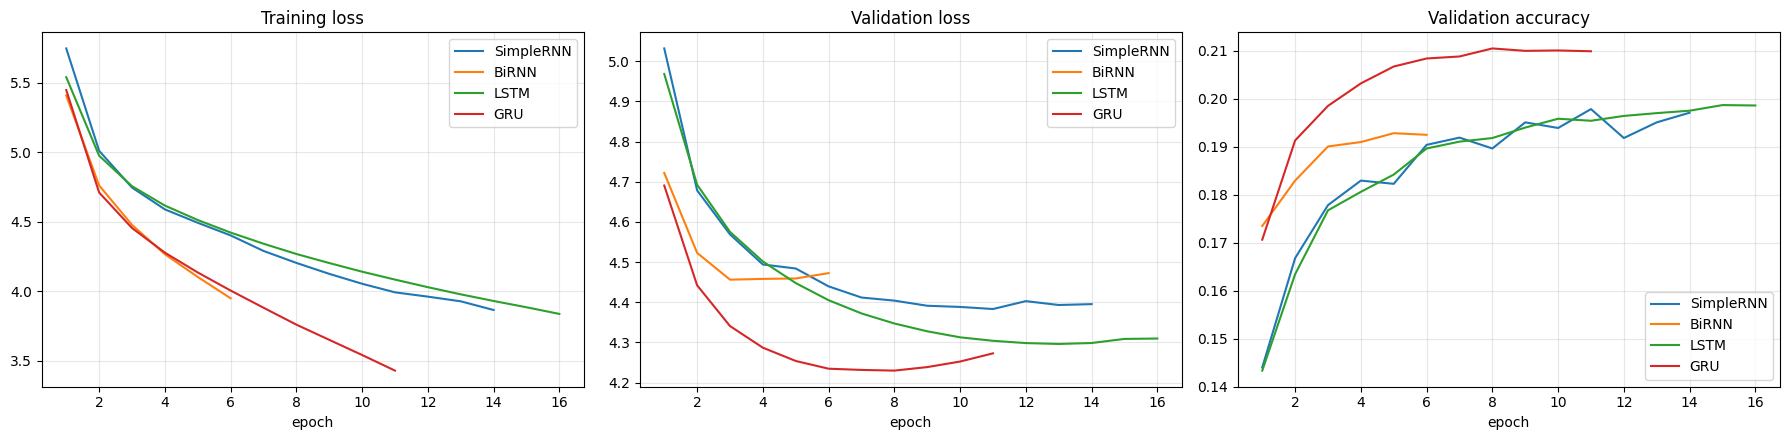

Saved: models/*.keras, results/model_comparison.csv, results/histories.json, results/training_curves.png


In [7]:
# Task (i) Part 2 - building and training SimpleRNN, Bidirectional RNN, LSTM and GRU
import os
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

# load the data saved in part 1
data = np.load("data/prepared.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]

with open("data/vocab.json") as f:
    info = json.load(f)
vocab_size = len(info["vocab"])
SEQ_LEN = info["seq_len"]
SEED = info["seed"]

# hyperparameters - same for all 4 models so the comparison is fair
EMBED_DIM = 128
UNITS = 256
DROPOUT = 0.3
BATCH_SIZE = 256
EPOCHS = 25        # maximum, early stopping usually stops before this
LR = 0.001
PATIENCE = 3


def get_rnn_layer(model_type):
    if model_type == "SimpleRNN":
        return layers.SimpleRNN(UNITS)
    elif model_type == "BiRNN":
        return layers.Bidirectional(layers.SimpleRNN(UNITS))
    elif model_type == "LSTM":
        return layers.LSTM(UNITS)
    elif model_type == "GRU":
        return layers.GRU(UNITS)


def build_model(model_type):
    keras.utils.set_random_seed(SEED)   # same starting weights for every model
    model = keras.Sequential(name=model_type)
    model.add(keras.Input(shape=(SEQ_LEN,), dtype="int32"))
    model.add(layers.Embedding(vocab_size, EMBED_DIM))
    model.add(get_rnn_layer(model_type))     # the only part that changes
    model.add(layers.Dropout(DROPOUT))
    model.add(layers.Dense(vocab_size, activation="softmax"))

    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR, clipnorm=1.0),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")])
    return model


# callback to record how long each epoch takes
class TimeHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.start)


os.makedirs("models", exist_ok=True)
model_names = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
results = []
all_history = {}

for name in model_names:
    print("\n" + "=" * 18, name, "=" * 18)
    model = build_model(name)
    time_cb = TimeHistory()
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                               restore_best_weights=True, verbose=1)

    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=EPOCHS,
                        batch_size=BATCH_SIZE,
                        callbacks=[early_stop, time_cb],
                        verbose=2)
    hist = history.history
    best_epoch = int(np.argmin(hist["val_loss"])) + 1

    # evaluate using the best weights (early stopping restores them)
    val_res = model.evaluate(X_val, y_val, batch_size=1024, verbose=0, return_dict=True)
    test_res = model.evaluate(X_test, y_test, batch_size=1024, verbose=0, return_dict=True)

    # perplexity = exp(cross-entropy loss)
    results.append({
        "Model": name,
        "Params": model.count_params(),
        "Epochs run": len(hist["loss"]),
        "Best epoch": best_epoch,
        "Train time (s)": round(sum(time_cb.times), 1),
        "Sec/epoch": round(float(np.mean(time_cb.times)), 1),
        "Train loss": round(hist["loss"][best_epoch - 1], 3),
        "Val loss": round(val_res["loss"], 3),
        "Val PPL": round(float(np.exp(val_res["loss"])), 1),
        "Test loss": round(test_res["loss"], 3),
        "Test PPL": round(float(np.exp(test_res["loss"])), 1),
        "Test acc": round(test_res["accuracy"], 4),
        "Test top-5": round(test_res["top5"], 4),
    })

    all_history[name] = {k: [float(v) for v in vals] for k, vals in hist.items()}
    model.save(f"models/{name}.keras")


# results table
results_df = pd.DataFrame(results).set_index("Model")
results_df.to_csv("results/model_comparison.csv")
with open("results/histories.json", "w") as f:
    json.dump(all_history, f)
print()
print(results_df.to_string())

# loss / accuracy curves
plots = [("loss", "Training loss"), ("val_loss", "Validation loss"), ("val_accuracy", "Validation accuracy")]
plt.figure(figsize=(18, 4.5))
for i, (key, title) in enumerate(plots):
    plt.subplot(1, 3, i + 1)
    for name in model_names:
        values = all_history[name][key]
        plt.plot(range(1, len(values) + 1), values, label=name)
    plt.title(title)
    plt.xlabel("epoch")
    plt.legend()
    plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/training_curves.png", dpi=150)
plt.show()
print("Saved: models/*.keras, results/model_comparison.csv, results/histories.json, results/training_curves.png")


################ SEED 1: "as to what you tell me of poor mary, it goes to my very heart. not even your"

--- temperature 0.2 ---
[SimpleRNN] own. i have not seen the first, and i have been seen to the first, and i have not seen a little, and i have seen the scene of the matter. i have not seen
[BiRNN    ] father, said he, and i have been to the room. i have not to the room. i have no doubt that i had a little man. but i have not to the room. i
[LSTM     ] own, and i have heard of the matter. i am sure that i have been a little man. i am afraid that i have a little man. i have not been a little man, and
[GRU      ] own. i have not seen it. i have no doubt that it is a most man. i have no doubt that i have been a little man. i have been a little man, said holmes

--- temperature 0.5 ---
[SimpleRNN] note. now, i understand. you have been on me that he has been been to be to be. well, said he, and the son of a man who is a man, said holmes
[BiRNN    ] majesty, said he, when it is the busi

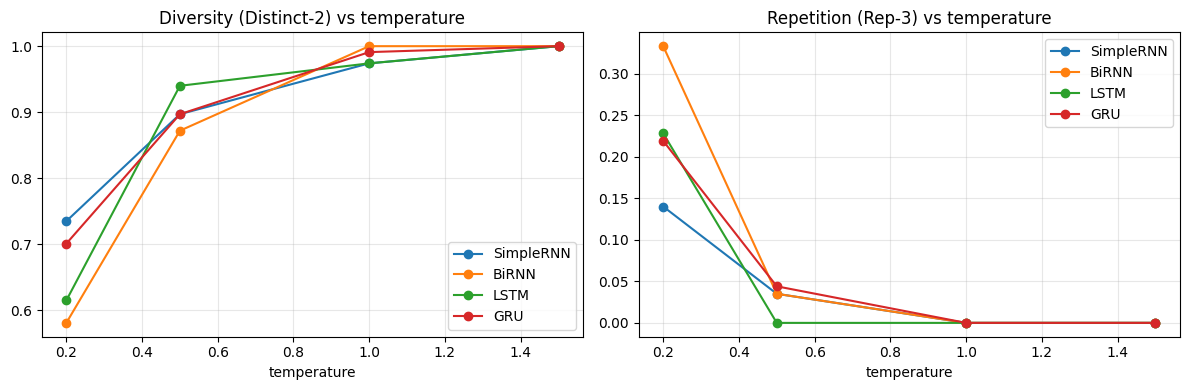

Saved: results/generated_samples.txt, results/generation_metrics.csv, results/temperature_effect.png


In [8]:
# Task (ii) + (iii) - generating text at different temperatures and comparing the models
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

with open("data/vocab.json") as f:
    info = json.load(f)
vocab = info["vocab"]
SEED = info["seed"]
X_test = np.load("data/prepared.npz")["X_test"]

model_names = ["SimpleRNN", "BiRNN", "LSTM", "GRU"]
models = {}
for name in model_names:
    models[name] = keras.models.load_model(f"models/{name}.keras")

temperatures = [0.2, 0.5, 1.0, 1.5]
GEN_LEN = 40               # number of words to generate
dot_id = vocab.index(".")


def ids_to_text(ids):
    text = " ".join(vocab[i] for i in ids)
    return re.sub(r" ([.,;:!?])", r"\1", text)    # remove the space before punctuation


# pick 3 seed sequences from the test text (never seen in training)
# each seed: 20 words, no <unk>, starting at the beginning of a sentence
seeds = []
for start in [500, 5000, 9500]:
    chosen = None
    for j in range(start, len(X_test)):
        if (X_test[j] != 0).all() and X_test[j - 1][0] == dot_id:
            chosen = j
            break
    if chosen is None:     # fallback: just avoid <unk>
        for j in range(start, len(X_test)):
            if (X_test[j] != 0).all():
                chosen = j
                break
    seeds.append(X_test[chosen])


def generate(model, seed_ids, temperature, rng):
    x = np.array(seed_ids, dtype=np.int32).reshape(1, -1)
    generated = []
    for _ in range(GEN_LEN):
        probs = model(x, training=False).numpy()[0].astype("float64")
        probs[0] = 0                                   # never generate <unk>
        # temperature: divide the log-probabilities by T and normalise again
        logits = np.log(probs + 1e-12) / temperature
        probs = np.exp(logits - np.max(logits))
        probs = probs / np.sum(probs)
        next_id = int(rng.choice(len(probs), p=probs))
        generated.append(next_id)
        # slide the window: drop the oldest word, add the new one
        x = np.append(x[:, 1:], [[next_id]], axis=1).astype(np.int32)
    return generated


def diversity_and_repetition(ids):
    bigrams = list(zip(ids, ids[1:]))
    trigrams = list(zip(ids, ids[1:], ids[2:]))
    distinct1 = len(set(ids)) / len(ids)               # unique words / total words
    distinct2 = len(set(bigrams)) / len(bigrams)       # unique word pairs / total pairs
    rep3 = 1 - len(set(trigrams)) / len(trigrams)      # fraction of repeated 3-word phrases
    return distinct1, distinct2, rep3


rows = []
output_lines = []
for s_num, seed in enumerate(seeds, start=1):
    output_lines.append(f'\n################ SEED {s_num}: "{ids_to_text(seed)}"')
    for T in temperatures:
        output_lines.append(f"\n--- temperature {T} ---")
        for name in model_names:
            rng = np.random.default_rng(SEED)   # same random numbers for every model -> fair comparison
            gen = generate(models[name], seed, T, rng)
            d1, d2, r3 = diversity_and_repetition(gen)
            rows.append({"Model": name, "Temp": T, "Seed": s_num,
                         "Distinct-1": d1, "Distinct-2": d2, "Rep-3": r3})
            output_lines.append(f"[{name:9s}] {ids_to_text(gen)}")

all_text = "\n".join(output_lines)
print(all_text)
with open("results/generated_samples.txt", "w") as f:
    f.write(all_text)

# average the metrics over the 3 seeds
df = pd.DataFrame(rows)
summary = df.groupby(["Model", "Temp"])[["Distinct-1", "Distinct-2", "Rep-3"]].mean().round(3)
summary.to_csv("results/generation_metrics.csv")
print("\n=== Average over 3 seeds (Distinct = diversity, higher = more varied | Rep-3 = repeated trigrams, higher = more repetitive) ===")
print(summary.unstack("Temp").to_string())

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for name in model_names:
    plt.plot(temperatures, summary.loc[name, "Distinct-2"], marker="o", label=name)
plt.title("Diversity (Distinct-2) vs temperature")
plt.xlabel("temperature")
plt.legend()
plt.grid(alpha=0.3)
plt.subplot(1, 2, 2)
for name in model_names:
    plt.plot(temperatures, summary.loc[name, "Rep-3"], marker="o", label=name)
plt.title("Repetition (Rep-3) vs temperature")
plt.xlabel("temperature")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/temperature_effect.png", dpi=150)
plt.show()
print("Saved: results/generated_samples.txt, results/generation_metrics.csv, results/temperature_effect.png")